# Product launch: sub-trees and a tornado chart

In Radiant: **Load example > Product launch**. Three trees: the main tree `product launch` with every variable, and two sub-trees, `launch` (what happens after a launch) and `test market` (a test market, then a launch decision).

## Example 5

> You are deciding whether to launch a new product. Launching costs $4 million (fixed cost) and each unit sold earns a $50 margin. Demand will be high (200,000 units) with probability 0.4, or low (20,000 units). Before deciding, you can run a test market for $300,000. A test market is not perfect: it comes back positive for 85% of products with high demand and for 20% of products with low demand. Should you launch now, test the market first, or not launch? What is the EMV of the best strategy, and which inputs matter most for that answer?

In [1]:
import pyrsm as rsm
from IPython.display import Markdown


def show(tree, final=True):
    """Draw a decision tree (Mermaid; rendered by JupyterLab, VS Code, Quarto)."""
    return Markdown(f"```mermaid\n{tree.to_mermaid(final=final)}\n```")

A branch can *be* another tree: `tree: launch` puts the tree `launch` at that branch. The branch keeps its own label, `p:` and `cost:`, and the combined tree is solved, printed and plotted as one. The sub-trees take their variables from the main tree (`variables: product launch`) so each part can also be calculated on its own.

In [2]:
product_launch = """name: Product launch
variables:
    fixed cost: 4000000
    margin: 50
    sales high: 200000
    sales low: 20000
    P(high): 0.4
    test cost: 300000
    P(pos|high): 0.85
    P(pos|low): 0.2
    P(pos): P(pos|high) * P(high) + P(pos|low) * (1 - P(high))
    P(high|pos): P(pos|high) * P(high) / P(pos)
    P(high|neg): (1 - P(pos|high)) * P(high) / (1 - P(pos))
type: decision
Launch now:
    tree: launch
Test market first:
    cost: test cost
    tree: test market
Do not launch:
    payoff: 0
"""

In [3]:
launch = """name: Launch
variables: product launch
cost: fixed cost
type: chance
High demand:
    p: P(high)
    payoff: margin * sales high
Low demand:
    p: 1 - P(high)
    payoff: margin * sales low
"""

After a test market the probability of high demand is no longer 0.4. `with:` sets values for one use of a tree: after a positive test `launch` is evaluated with `P(high)` equal to `P(high|pos)` (Bayes' rule, in the main tree's variables).

In [4]:
test_market = """name: Test market
variables: product launch
type: chance
Positive result:
    p: P(pos)
    type: decision
    Launch:
        tree: launch
        with:
            P(high): P(high|pos)
    Do not launch:
        payoff: 0
Negative result:
    p: 1 - P(pos)
    type: decision
    Launch:
        tree: launch
        with:
            P(high): P(high|neg)
    Do not launch:
        payoff: 0
"""

In [5]:
trees = {"product launch": product_launch, "launch": launch, "test market": test_market}
tree = rsm.decide.dtree(product_launch, subtree_library=trees)
tree.summary(input=False, output=True)

Variable input values:
                           
fixed cost  4000000.0000000
margin           50.0000000
sales high   200000.0000000
sales low     20000.0000000
P(high)           0.4000000
test cost    300000.0000000
P(pos|high)       0.8500000
P(pos|low)        0.2000000
P(pos)            0.4600000
P(high|pos)       0.7391304
P(high|neg)       0.1111111

Trees used:
  Launch now uses 'launch': 600,000.00
  Test market first uses 'test market': 1,380,000.00
  Test market first > Positive result > Launch uses 'launch' with P(high) = 0.7391: 3,652,173.91
  Test market first > Negative result > Launch uses 'launch' with P(high) = 0.1111: -2,000,000.00

Initial decision tree:
                             Probability        Payoff         Cost     Type
 Product launch                                                             
  ¦--Launch now                                        4,000,000.00 decision
  ¦   ¦--High demand             40.00 % 10,000,000.00                chance
  ¦   °--

Test the market first: EMV **$1,380,000**, against $600,000 for launching right away. Launch only after a positive test. `tree_uses` lists each use of a sub-tree and the EMV it contributes:

In [6]:
import pandas as pd
pd.DataFrame(tree.tree_uses)

,tree,at,with,emv
0,launch,"[Product launch, Launch now]",{},6.000000e+05
1,test market,"[Product launch, Test market first]",{},1.380000e+06
2,launch,"[Product launch, Test market first, Positive result, Launch]",{'P(high)': 0.7391304347826088},3.652174e+06
3,launch,"[Product launch, Test market first, Negative result, Launch]",{'P(high)': 0.11111111111111112},-2.000000e+06


The plot draws each sub-tree in its own box. In JupyterLab, VS Code and Radiant, hovering over a node shows how its value was calculated.

In [7]:
show(tree)

```mermaid
graph LR
    n1["$1,380,000.00"]
    n1 --- |"Launch now"| n2
    n2(("$600,000.00"))
    n2 --- |"High demand: p=0.4000"| n3
    n3["$10,000,000.00"]
    n2 --- |"Low demand: p=0.6000"| n4
    n4["$1,000,000.00"]
    n1 === |"Test market first"| n5
    n5(("$1,380,000.00"))
    n5 --- |"Positive result: p=0.4600"| n6
    n6["$3,652,173.91"]
    n6 === |"Launch"| n7
    n7(("$3,652,173.91"))
    n7 --- |"High demand: p=0.7391"| n8
    n8["$10,000,000.00"]
    n7 --- |"Low demand: p=0.2609"| n9
    n9["$1,000,000.00"]
    n6 --- |"Do not launch"| n10
    n10["$0.00"]
    n5 --- |"Negative result: p=0.5400"| n11
    n11["$0.00"]
    n11 --- |"Launch"| n12
    n12(("-$2,000,000.00"))
    n12 --- |"High demand: p=0.1111"| n13
    n13["$10,000,000.00"]
    n12 --- |"Low demand: p=0.8889"| n14
    n14["$1,000,000.00"]
    n11 === |"Do not launch"| n15
    n15["$0.00"]
    n1 --- |"Do not launch"| n16
    n16["$0.00"]
    subgraph tree1 ["launch"]
        n2
        n3
        n4
    end
    subgraph tree2 ["test market"]
        n5
        n6
        subgraph tree3 ["launch · P(high) = 0.7391"]
            n7
            n8
            n9
        end
        n10
        n11
        subgraph tree4 ["launch · P(high) = 0.1111"]
            n12
            n13
            n14
        end
        n15
    end
    style tree1 fill:#f8f9fa,stroke:#6c757d,stroke-width:1px,stroke-dasharray:3 3
    style tree2 fill:#f8f9fa,stroke:#6c757d,stroke-width:1px,stroke-dasharray:3 3
    style tree3 fill:#f8f9fa,stroke:#6c757d,stroke-width:1px,stroke-dasharray:3 3
    style tree4 fill:#f8f9fa,stroke:#6c757d,stroke-width:1px,stroke-dasharray:3 3
    classDef decision fill:#9ACD32,stroke:#333,stroke-width:1px;
    class n1,n6,n11 decision;
    classDef chance_with_cost fill:#FF8C00,stroke:#333,stroke-width:3px,stroke-dasharray:4 5;
    class n2,n5,n7,n12 chance_with_cost;
    %% chosen branches drawn with === (highlighted in final tree)
    click n1 callback "<b>Product launch</b> Decision node<br><b>Options</b> Launch now $600,000.00; Test market first $1,380,000.00; Do not launch $0.00<br><b>Choose</b> Test market first (highest value)"
    click n2 callback "<b>Launch now</b> Chance node<br><b>Tree</b> launch<br><b>Cost</b> fixed cost = $4,000,000.00<br><b>EMV</b> 0.4 × $10,000,000.00 + 0.6 × $1,000,000.00 − $4,000,000.00 = $600,000.00"
    click n3 callback "<b>High demand</b> End node<br><b>p</b> P(high) = 0.4<br><b>Payoff</b> margin * sales high = $10,000,000.00"
    click n4 callback "<b>Low demand</b> End node<br><b>p</b> 1 - P(high) = 0.6<br><b>Payoff</b> margin * sales low = $1,000,000.00"
    click n5 callback "<b>Test market first</b> Chance node<br><b>Tree</b> test market<br><b>Cost</b> test cost = $300,000.00<br><b>EMV</b> 0.46 × $3,652,173.91 + 0.54 × $0.00 − $300,000.00 = $1,380,000.00"
    click n6 callback "<b>Positive result</b> Decision node<br><b>p</b> P(pos) = 0.46<br><b>Options</b> Launch $3,652,173.91; Do not launch $0.00<br><b>Choose</b> Launch (highest value)"
    click n7 callback "<b>Launch</b> Chance node<br><b>Tree</b> launch<br><b>With</b> P(high) = 0.7391<br><b>Cost</b> fixed cost = $4,000,000.00<br><b>EMV</b> 0.7391 × $10,000,000.00 + 0.2609 × $1,000,000.00 − $4,000,000.00 = $3,652,173.91"
    click n8 callback "<b>High demand</b> End node<br><b>p</b> P(high) = 0.7391<br><b>Payoff</b> margin * sales high = $10,000,000.00"
    click n9 callback "<b>Low demand</b> End node<br><b>p</b> 1 - P(high) = 0.2609<br><b>Payoff</b> margin * sales low = $1,000,000.00"
    click n10 callback "<b>Do not launch</b> End node<br><b>Payoff</b> $0.00"
    click n11 callback "<b>Negative result</b> Decision node<br><b>p</b> 1 - P(pos) = 0.54<br><b>Options</b> Launch -$2,000,000.00; Do not launch $0.00<br><b>Choose</b> Do not launch (highest value)"
    click n12 callback "<b>Launch</b> Chance node<br><b>Tree</b> launch<br><b>With</b> P(high) = 0.1111<br><b>Cost</b> fixed cost = $4,000,000.00<br><b>EMV</b> 0.1111 × $10,000,000.00 + 0.8889 × $1,000,000.00 − $4,000,000.00 = -$2,000,000.00"
    click n13 callback "<b>High demand</b> End node<br><b>p</b> P(high) = 0.1111<br><b>Payoff</b> margin * sales high = $10,000,000.00"
    click n14 callback "<b>Low demand</b> End node<br><b>p</b> 1 - P(high) = 0.8889<br><b>Payoff</b> margin * sales low = $1,000,000.00"
    click n15 callback "<b>Do not launch</b> End node<br><b>Payoff</b> $0.00"
    click n16 callback "<b>Do not launch</b> End node<br><b>Payoff</b> $0.00"
```

## How sure are we? One variable

How does the best strategy change with the probability of high demand? Below 0.2 do not launch, above 0.6 launch right away, and in between test the market first.

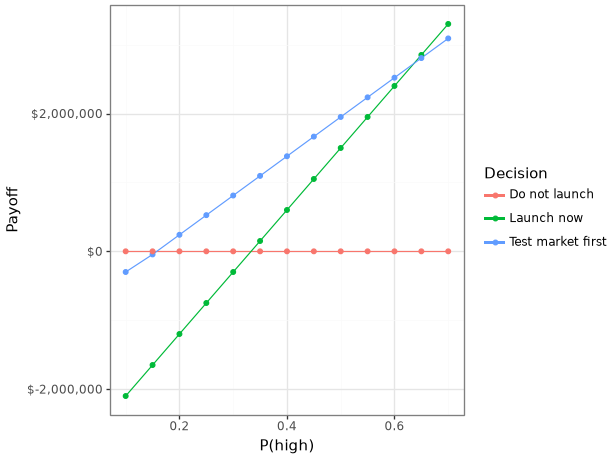

In [8]:
sens = tree.sensitivity({"P(high)": {"min": 0.1, "max": 0.7, "step": 0.05}})
sens.plot(["Launch now", "Test market first", "Do not launch"])

## Several variables at once: a tornado chart

Set each variable to a low and a high value, one at a time, with the others at their base values. The bars show how far the EMV moves; the longest bar is the input that matters most.

In [9]:
tor = tree.tornado({
    "P(high)": (0.3, 0.5),
    "margin": (40, 60),
    "fixed cost": (3_500_000, 4_500_000),
    "P(pos|high)": (0.75, 0.95),
    "test cost": (200_000, 400_000),
})
tor.to_frame()

,variable,base,low,high,EMV low,EMV high,swing,decision low,decision high
0,margin,50.00,40.00,60.00,676000.0,2084000.0,1408000.0,Test market first,Test market first
1,P(high),0.40,0.30,0.50,810000.0,1950000.0,1140000.0,Test market first,Test market first
2,P(pos|high),0.85,0.75,0.95,1140000.0,1620000.0,480000.0,Test market first,Test market first
3,fixed cost,4000000.00,3500000.00,4500000.00,1610000.0,1150000.0,460000.0,Test market first,Test market first
4,test cost,300000.00,200000.00,400000.00,1480000.0,1280000.0,200000.0,Test market first,Test market first


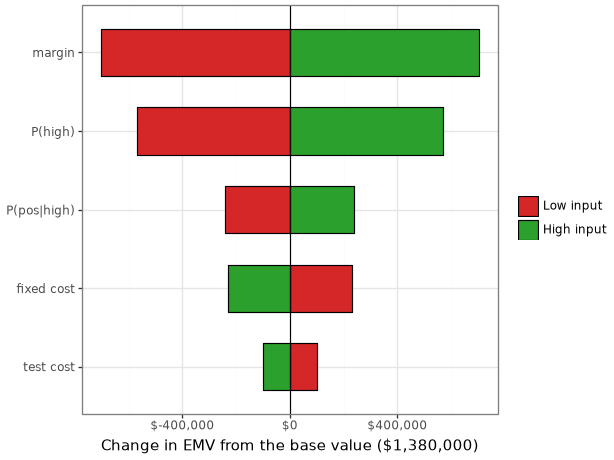

In [10]:
tor.plot()

The margin and the probability of high demand move the EMV the most, but within these ranges the decision stays the same: test the market first. Getting a better estimate of the margin is worth more than haggling over the cost of the test.